In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import re

In [2]:
!python PyData_from_Markdown.py Table.md Table.py

Successfully generated Table.py with 47 papers


In [3]:
from Table import PaperData, papers_list

# Configure style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 7)

In [4]:
# Initialize collector
papers = PaperData()

for paper in papers_list:
    papers.add_entry(paper)

# Convert to DataFrame when ready for analysis
research_df = papers.to_dataframe()

In [5]:
print("DataFrame created with {} entries.".format(len(research_df)))

DataFrame created with 47 entries.


## Basic graphs

In [6]:
# Plot the number of papers per year
fig1 = px.histogram(research_df, x='Year', title='Number of Papers per Year')
fig1.show()

In [7]:
# Function to print a Pie chart
# textinfo can be 'value', 'percent', 'label', or 'text'
def pie_chart(dataframe, column, title, textinfo='value'):
    """
    Create a pie chart from the specified column of the DataFrame.
    """
    fig = px.pie(
        dataframe, 
        names=column, 
        title=title,
        hole=0,
        color_discrete_sequence=px.colors.qualitative.Bold,
    )
    fig.update_traces(
        marker=dict(line=dict(color='#000000', width=2)),
        textinfo=textinfo,
        textfont=dict(size=16),
    )
    fig.update_layout(
        legend_title_text='Network Type',
        margin=dict(t=50, b=50, l=50, r=50),
    )
    fig.show()

In [8]:
# Create a copy of the dataframe for visualization
tmp_df = research_df['Network Type/s'].str.replace('\n---1---\n', ' or ')

pie_chart(tmp_df, 'Network Type/s', 'Distribution of NN Types per Paper')

In [9]:
# Replace None values with "Unknown" for better visualization
tmp_df = research_df['Accelerator Architecture'].fillna("Unknown")
pie_chart(tmp_df, 'Accelerator Architecture', 'Distribution of Accelerator Architectures per Paper')

In [10]:
# Replace None values with "Unknown" for better visualization
tmp_df = research_df['FPGA Vendor'].fillna("Unknown")
pie_chart(tmp_df, 'FPGA Vendor', 'Distribution of FPGA Vendors per Paper', textinfo='value')

In [11]:
# Function to replace HDL values with "Unknown HDL"
def replace_hdl(val):
    if isinstance(val, str) and val == 'HDL':
        return 'Unknown HDL'
    return val
# Apply the function to the 'Hardware Description' column
tmp_df = research_df['Hardware Description'].apply(replace_hdl)
# Replace None values with "Unknown" for better visualization
tmp_df = tmp_df.fillna("Unknown")

pie_chart(tmp_df, 'Hardware Description', 'Distribution of Hardware Description Methods per Paper')

In [12]:
# Replace None values with "Unknown" for better visualization
tmp_df = research_df['FPGA Vendor'].fillna("Unknown")
pie_chart(tmp_df, 'FPGA Vendor', 'Distribution of FPGA Vendors per Paper')

In [13]:
tmp_df = research_df["Training Method"].dropna()
pie_chart(tmp_df, 'Training Method', 'Distribution of Training Methods per Paper')

## Deterministic analysis

In [14]:
def split_data_rows(df, split_string):
    # Create a new DataFrame to store the split data
    is_split = False
    new_rows = []
    for _, row in df.iterrows():
        new_rows_tmp = []
        for col in df.columns:
            if (not row[col] == None) and (split_string in row[col]):
                parts = row[col].split(split_string)
                for index, part in enumerate(parts):
                    if not is_split:
                        new_row = row.copy()
                        new_row[col] = part.strip()
                        new_rows_tmp.append(new_row)
                    else:
                        #print(row)
                        new_rows_tmp[index][col] = part.strip()
                is_split = True
        new_rows.extend(new_rows_tmp)
        if not is_split:
            new_rows.append(row)
        is_split = False

    new_df = pd.DataFrame(new_rows)
    return new_df

def pre_process_data(df):
    """
    Pre-process the DataFrame to prepare it for analysis.
    """
    # Replace commas in numeric strings
    for col in df.columns:
        if df[col].dtype == 'object':
            # Handle newlines within parentheses using DOTALL mode ((?s))
            df[col] = df[col].str.replace(r'(?s)\([^)]*\)', '', regex=True).str.strip()
            # Clean up special characters that might cause parsing issues
            df[col] = df[col].str.replace(',', '')
            df[col] = df[col].str.replace('*', '')
            df[col] = df[col].str.replace('$', '')
            df[col] = df[col].str.replace('approx', '')
            df[col] = df[col].str.strip()
    
    # Look for all ------- and split data row in two rows, copying the common part
    df = split_data_rows(df, '-------')
    df = split_data_rows(df, '---1---')
    df = split_data_rows(df, '---2---')

    return df

In [15]:
# Pre-process the DataFrame for analysis
df_for_analysis = pre_process_data(research_df)
# Display the first few rows of the cleaned DataFrame
print("DataFrame created with {} entries.".format(len(df_for_analysis)))

DataFrame created with 81 entries.


In [16]:
# Function to print scatter plot
def fancy_scatter_plot(dataframe, x_col, y_col, title, hue=None, x_log=False, y_log=False, legend_x=1, legend_y=1, legend_xanchor='auto', legend_yanchor='auto'):
    """
    Create a scatter plot from the specified columns of the DataFrame.
    """
    fig = px.scatter(
        dataframe, 
        x=x_col, 
        y=y_col, 
        title=title,
        color=hue,
        log_x=x_log,
        log_y=y_log,
        color_discrete_sequence=px.colors.qualitative.Bold,
    )
    fig.update_traces(
        marker=dict(line=dict(color='#000000', width=2)),
        textfont=dict(size=16),
    )
    legend_dict = dict(
        orientation="v",
        yanchor=legend_yanchor,
        y=legend_y,
        xanchor=legend_xanchor,
        x=legend_x,
    )
    fig.update_layout(
        legend_title_text=hue,
        margin=dict(t=50, b=50, l=50, r=50),
        legend=legend_dict,
        legend_bgcolor='rgba(255, 255, 255, 0.7)',  # White background with 70% opacity
        legend_bordercolor='rgba(0, 0, 0, 0.5)'     # Black border with 50% opacity
    )
    fig.show()

def scatter_plot(dataframe, x_col, y_col, title, hue=None, x_log=False, y_log=False, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper'):
    plt.figure()
    sns.scatterplot(data=dataframe, x=x_col, y=y_col, hue=hue)
    if x_log:
        plt.xscale('log')
    if y_log:
        plt.yscale('log')
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.title(title)
    plt.legend(title=hue, bbox_to_anchor=(legend_x, legend_y), loc=f'{legend_yanchor} {legend_xanchor}')
    plt.show()

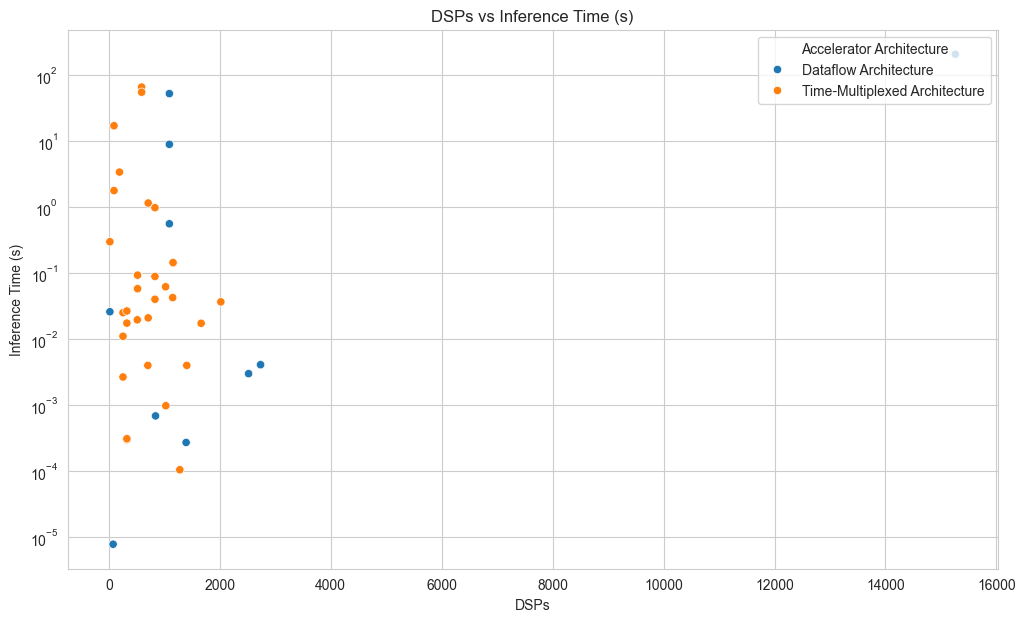

In [17]:
# Function to convert energy units to Seconds
def convert_time_units(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(\.\d+)?)\s*(s|ms|mu s)', value)
        if match:
            num_value = float(match.group(1))
            unit = match.group(3)
            if unit == 'ms':
                return num_value / 1000  # Convert ms to s
            elif unit == 'mu s':
                return num_value / 1e6  # Convert us to s
            else:
                return num_value  # Already in Seconds
    return None

# Function to extract DSPs and convert latency to milliseconds
def extract_dsp(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(\.\d+)?)\s*(DSP|DSPs)', value)
        if match:
            num_value = float(match.group(1))
            return num_value
    return None

# Apply the function to extract DSPs and latency
temp_df = df_for_analysis[['FPGA Resources Consumption', 'Inference Time (Latency)', 'Accelerator Architecture']].dropna()
temp_df['Inference Time (s)'] = temp_df['Inference Time (Latency)'].apply(convert_time_units)
temp_df['DSPs'] = temp_df['FPGA Resources Consumption'].apply(extract_dsp)
# Remove rows with NaN values
temp_df = temp_df.dropna()
# Plot the data with a logarithmic scale on the y-axis and different colors for 'Accelerator Architecture'
scatter_plot(temp_df, 'DSPs', 'Inference Time (s)', 'DSPs vs Inference Time (s)', hue='Accelerator Architecture', x_log=False, y_log=True)
fancy_scatter_plot(temp_df, 'DSPs', 'Inference Time (s)', 'DSPs vs Inference Time (s)', hue='Accelerator Architecture', x_log=False, y_log=True)


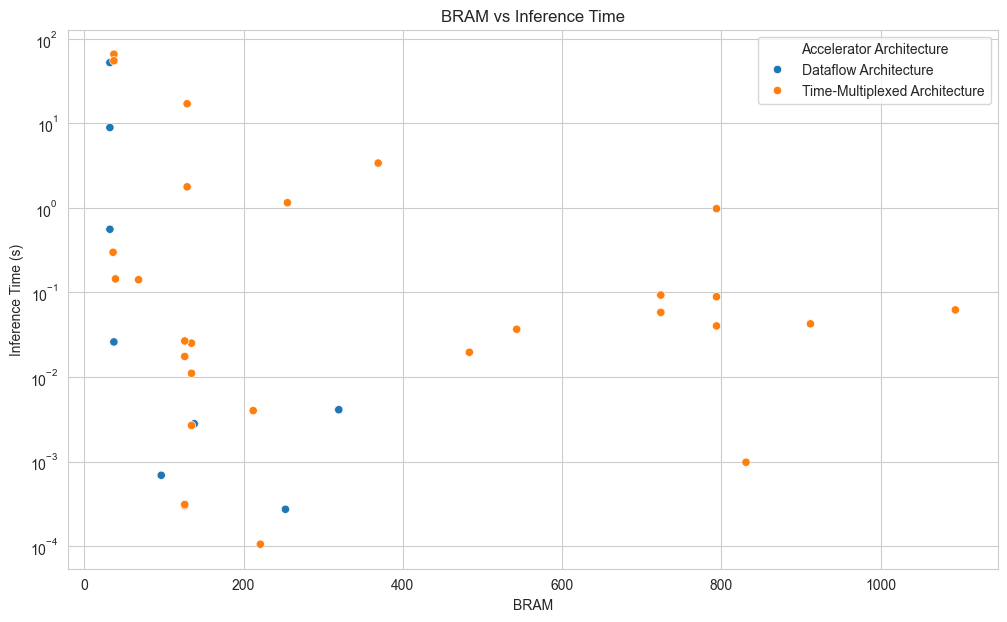

In [18]:
# Function to extract BRAM and convert latency to milliseconds
def extract_bram(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(\.\d+)?)\s*(BRAM|BRAMs)', value)
        if match:
            num_value = float(match.group(1))
            return num_value
    return None

# Apply the function to extract BRAM and latency
temp_df = df_for_analysis[['FPGA Resources Consumption', 'Inference Time (Latency)', 'Accelerator Architecture']].dropna()
temp_df['Inference Time (s)'] = temp_df['Inference Time (Latency)'].apply(convert_time_units)
temp_df['BRAM'] = temp_df['FPGA Resources Consumption'].apply(extract_bram)
# Remove rows with NaN values
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'BRAM', 'Inference Time (s)', 'BRAM vs Inference Time', hue='Accelerator Architecture', x_log=False, y_log=True)

## Energy related graphs

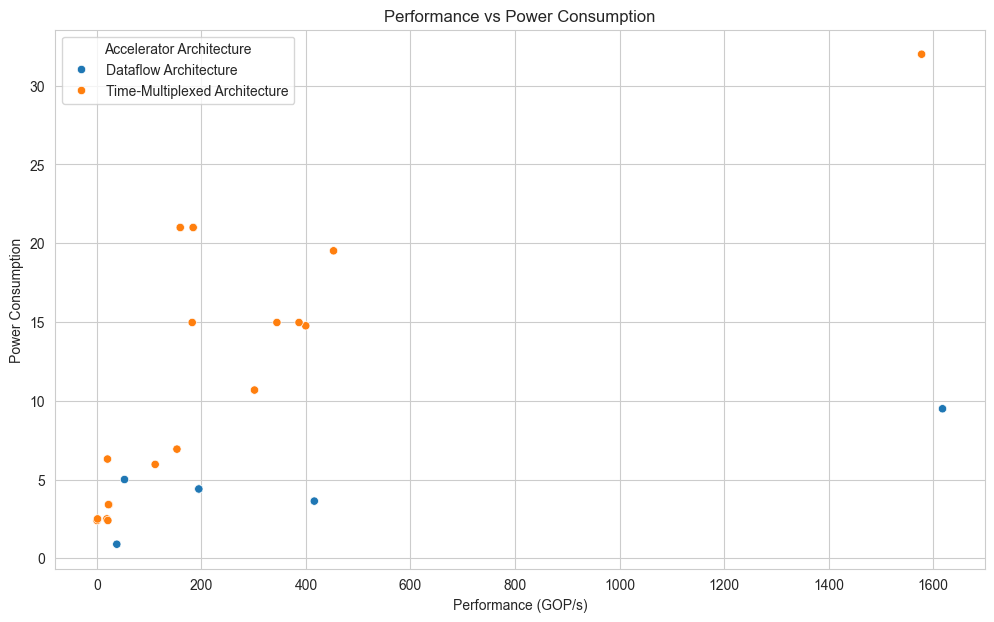

In [19]:
# Apply the function to extract BRAM and latency
temp_df = df_for_analysis[['Performance (GOP/s)', 'Power Consumption', 'Accelerator Architecture']].dropna()

# Extract numeric values from 'Performance (GOP/s)' and convert to float
temp_df['Performance (GOP/s)'] = temp_df['Performance (GOP/s)'].str.extract(r'(\d+(\.\d+)?)')[0].astype(float)
# Extract numeric values from 'Power Consumption' and convert to float
temp_df['Power Consumption'] = temp_df['Power Consumption'].str.extract(r'(\d+(\.\d+)?)')[0].astype(float)

scatter_plot(temp_df, 'Performance (GOP/s)', 'Power Consumption', 'Performance vs Power Consumption', hue='Accelerator Architecture', x_log=False, y_log=False, legend_x=0, legend_y=1, legend_xanchor='left', legend_yanchor='upper')

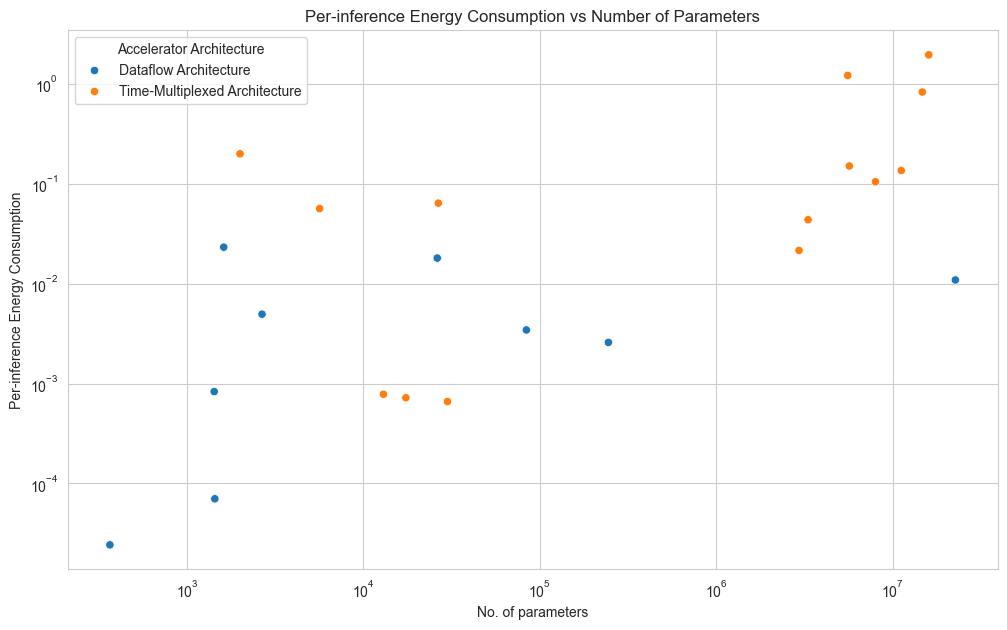

In [20]:
# Function to convert energy units to Joules
def convert_energy_units(value):
    if isinstance(value, str):
        # Extract numeric value and unit
        match = re.search(r'(\d+(\.\d+)?)\s*(J|mJ|mu J)', value)
        if match:
            num_value = float(match.group(1))
            unit = match.group(3)
            if unit == 'mJ':
                return num_value / 1000  # Convert mJ to J
            elif unit == 'mu J':
                return num_value / 1e6  # Convert uJ to J
            else:
                return num_value  # Already in Joules
    return None

# Apply the function to extract BRAM and latency
temp_df = df_for_analysis[['Per-inference Energy Consumption', 'No. of parameters', 'Accelerator Architecture']].dropna()

# Extract numeric values from 'Performance (GOP/s)' and convert to float
temp_df['Per-inference Energy Consumption'] = temp_df['Per-inference Energy Consumption'].apply(convert_energy_units)
# Extract numeric values from 'Power Consumption' and convert to float
temp_df['No. of parameters'] = temp_df['No. of parameters'].str.extract(r'(\d+(\.\d+)?)')[0].astype(float)

scatter_plot(temp_df, 'No. of parameters', 'Per-inference Energy Consumption', 'Per-inference Energy Consumption vs Number of Parameters', hue='Accelerator Architecture', x_log=True, y_log=True, legend_x=0, legend_y=1, legend_xanchor='left', legend_yanchor='upper')

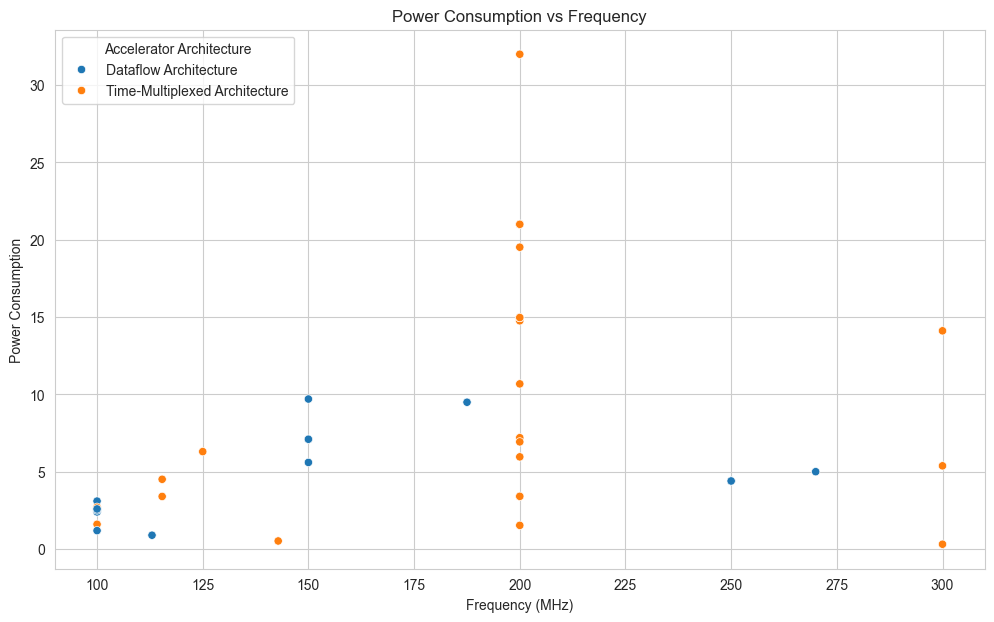

In [21]:
# Apply the function to extract BRAM and latency
temp_df = df_for_analysis[['Power Consumption', 'Frequency (MHz)', 'Accelerator Architecture']].dropna()

# Extract numeric values from 'Power Consumption' and convert to float
temp_df['Power Consumption'] = temp_df['Power Consumption'].str.extract(r'(\d+(\.\d+)?)')[0].astype(float)
# Extract numeric values from 'Frequency (MHz)' and convert to float
temp_df['Frequency (MHz)'] = temp_df['Frequency (MHz)'].str.extract(r'(\d+(\.\d+)?)')[0].astype(float)

scatter_plot(temp_df, 'Frequency (MHz)', 'Power Consumption', 'Power Consumption vs Frequency', hue='Accelerator Architecture', x_log=False, y_log=False, legend_x=0, legend_y=1, legend_xanchor='left', legend_yanchor='upper')

We can see from the figure Dataflow accelerators tend to function at a lower frequencies than the time-multiplexed accelerators. Furthemore, the frequencies vary from 100 to 300 MHz, some Time-Multiplexed accelerators used a faster working frequency for the DSPs than for the other logic which included interconnects.

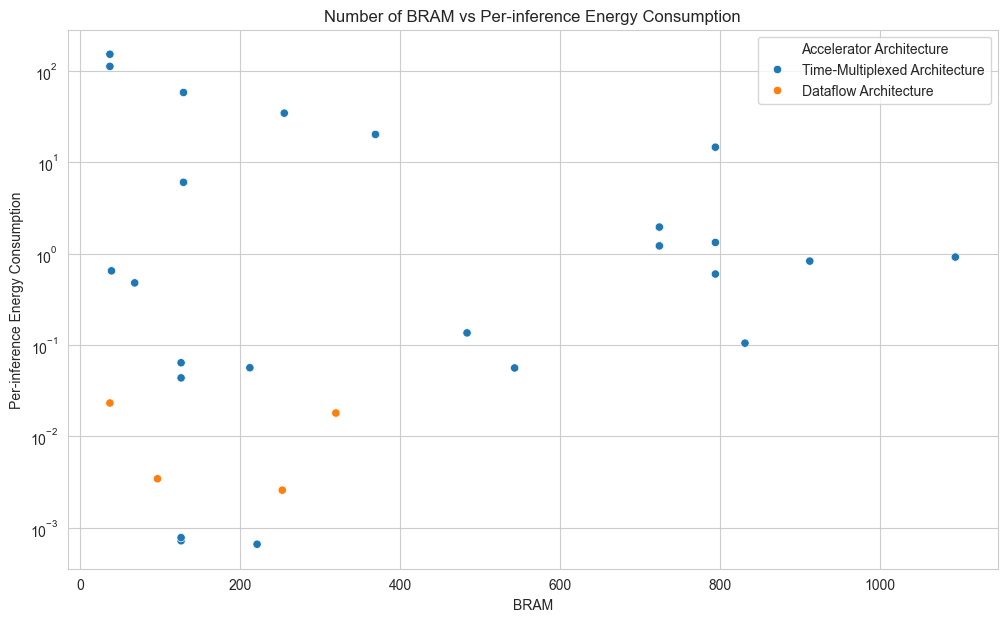

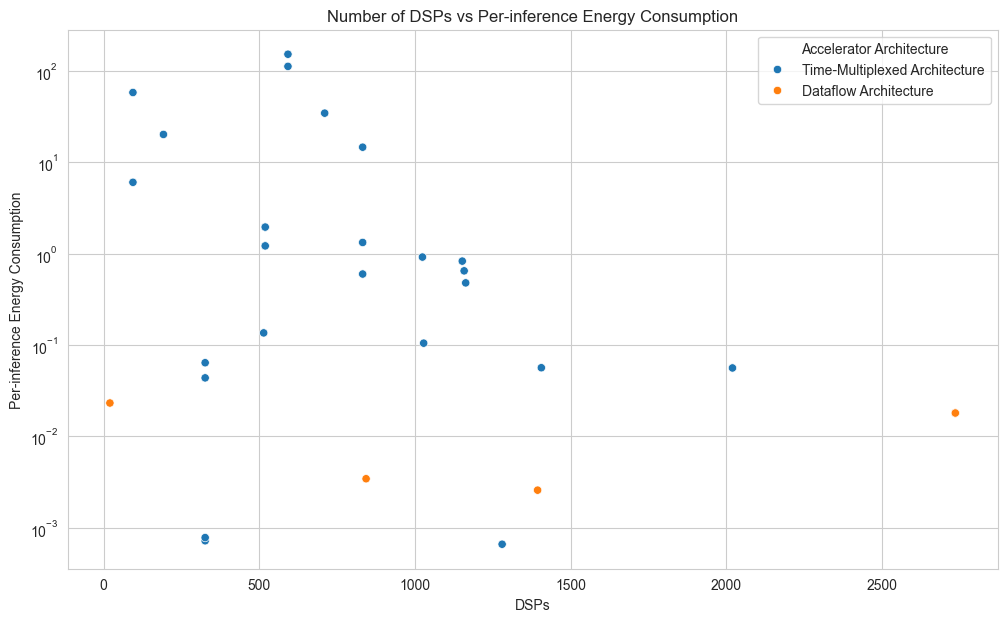

In [22]:
# Apply the function to extract DSPs and latency
temp_df = df_for_analysis[['FPGA Resources Consumption', 'Per-inference Energy Consumption', 'Accelerator Architecture']].dropna()
temp_df['Per-inference Energy Consumption'] = temp_df['Per-inference Energy Consumption'].apply(convert_energy_units)
temp_df['DSPs'] = temp_df['FPGA Resources Consumption'].apply(extract_dsp)
temp_df['BRAM'] = temp_df['FPGA Resources Consumption'].apply(extract_bram)
# Remove rows with NaN values
temp_df = temp_df.dropna()

scatter_plot(temp_df, 'BRAM', 'Per-inference Energy Consumption', 'Number of BRAM vs Per-inference Energy Consumption', hue='Accelerator Architecture', x_log=False, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')

scatter_plot(temp_df, 'DSPs', 'Per-inference Energy Consumption', 'Number of DSPs vs Per-inference Energy Consumption', hue='Accelerator Architecture', x_log=False, y_log=True, legend_x=1, legend_y=1, legend_xanchor='right', legend_yanchor='upper')